In [1]:
import django, os
os.environ.setdefault('DJANGO_SETTINGS_MODULE', 'rest.settings')
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

django.setup()

In [2]:
from datetime import datetime
time0=datetime.now().timestamp()
from mockat.tools import tle,sat_pos
qth=(15,50,200)
#import predict
#times=[predict.observe(tle, qth, at=time0+i*60*30) for i in range(3)]
mupos=[sat_pos(time0+i*60*30, ret=-1) for i in range(3)]


In [3]:
from mockat import tools
import importlib
importlib.reload(tools)

<module 'mockat.tools' from '/home/limu/Public/alphive/mockat/tools.py'>

In [4]:
from astropy import coordinates as coor
loc=sat_pos(time0,-1)#.transformto(coor.FK5)

In [6]:
[a.value for a in loc.to_geocentric()]

[np.float64(1304673.4503671434),
 np.float64(-4977038.326142782),
 np.float64(4559143.419319775)]

In [77]:
def perp(time0):
    import numpy as np
    tovec=lambda b:np.array([b.x.value,b.y.value,b.z.value])
    mupos=[sat_pos(time0+i*60*30, ret=-1) for i in range(3)]
    tovec=lambda b:np.array([a.value for a in b.to_geocentric()])
    muvec=[tovec(m) for m in mupos]
    c=np.cross(muvec[1]-muvec[0],muvec[2]-muvec[1])
    norm=lambda c:np.sqrt(sum(c**2))
    return c/norm(c)
allvec=np.array([perp(time0+24*60*60*i) for i in range(0,300,3)])

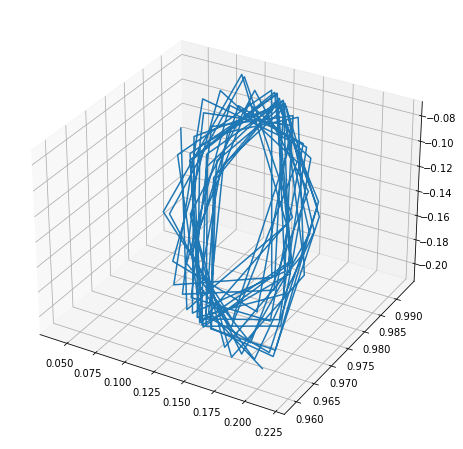

In [78]:
from matplotlib import pyplot as pl
fig = pl.figure(figsize=(8,8))
ax = pl.axes(projection='3d')

ax.plot3D(allvec[:,0],allvec[:,1],allvec[:,2])

In [30]:
allvec2=np.array([perp(time0+1e4+24*60*60*i) for i in range(0,300,3)])

In [32]:
allvec[0]-allvec2[0]

array([-0.73847938,  0.38254681,  0.02975043])

In [7]:
import predict

In [8]:
gomes=[predict.observe(tle, qth, at=time0+i*60*30) for i in range(3)]

In [9]:
vecprod=lambda muvec:np.cross(muvec[1]-muvec[0],muvec[2]-muvec[1])

def perp2(time0):
    gomes=[predict.observe(tle, qth, at=time0+i*60*30) for i in range(3)]
    zovec=lambda p,d:np.array([np.cos(p)*np.sin(d),np.cos(p)*np.sin(d),np.sin(p)])
    fovec=[zovec(np.deg2rad(g['latitude']),np.deg2rad(g['longitude'])) for g in gomes]
    return vecprod(fovec)



In [45]:
perp2=lambda muvec:np.cross(muvec[1]-muvec[0],muvec[2]-muvec[1])
perp2(fovec)

array([ 0.10073412, -0.10073412,  0.        ])

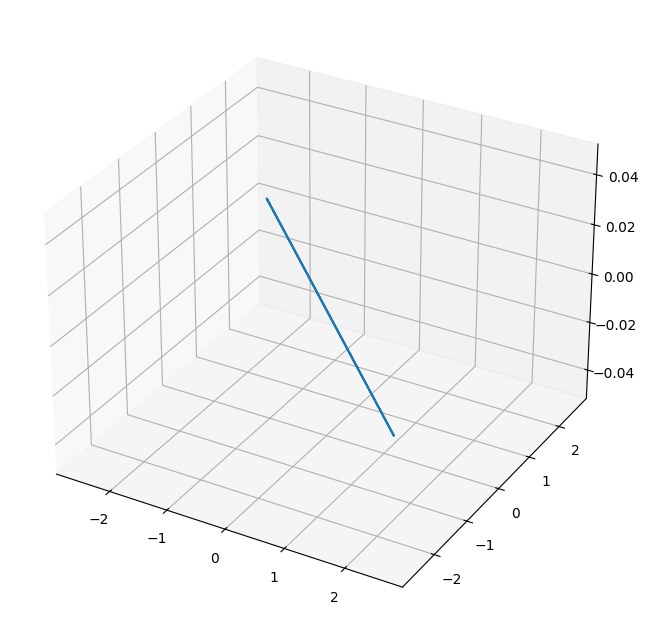

In [14]:
import numpy as np
zavec=np.array([perp2(time0+100*i) for i in range(864)])
from matplotlib import pyplot as pl
fig = pl.figure(figsize=(8,8))
ax = pl.axes(projection='3d')
ax.plot3D(zavec[:,0],zavec[:,1],zavec[:,2])

In [15]:
from astropy import units as u
sky=coor.FK5(*zavec[0]*u.m,representation_type='cartesian')
#sky.set_representation_cls()
sky

<FK5 Coordinate (equinox=J2000.000): (x, y, z) in m
    (-2.45109768, 2.45109768, 0.)>

In [16]:
sky.set_representation_cls()